In [1]:
import rasterio
import matplotlib.pyplot as plt
import geopandas as gpd
import pyogrio

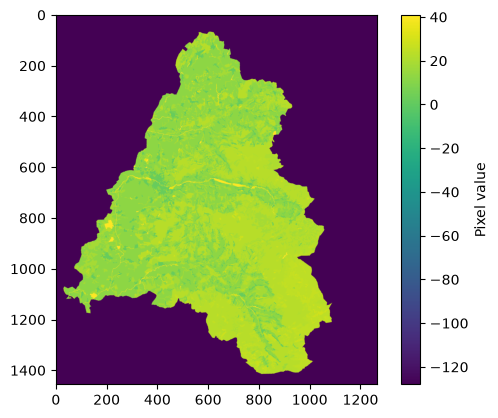

In [13]:
with rasterio.open(r"raw_data\land_use.tif") as src:
    band = src.read(1)

plt.imshow(band, cmap="viridis")
plt.colorbar(label="Pixel value")
plt.show()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

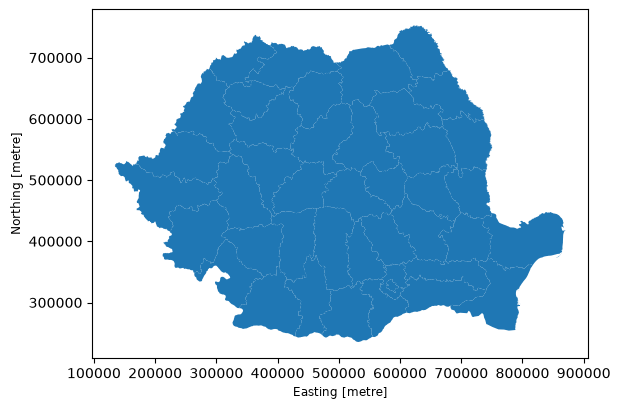

In [14]:
path = r"raw_data/Judete.gpkg"
judete_gdf = gpd.read_file(path)
judete_gdf.plot()

In [15]:
judete_gdf.head()

,countyId,countyCode,name,mnemonic,regionId,regionCode,region,sortCode,version,geometry
0,2,29,Arad,AR,5,859,Vest,2,2025-03-26,"POLYGON ((321516.84 547745.33, 321500.12 54764..."
1,3,38,Argeș,AG,3,831,Sud,3,2025-03-26,"POLYGON ((525302.72 431309.95, 525308.12 43129..."
2,4,47,Bacău,BC,1,813,Nord-Est,4,2025-03-26,"POLYGON ((668591.31 587936.67, 668619.148 5878..."
3,5,56,Bihor,BH,6,868,Nord-Vest,5,2025-03-26,"POLYGON ((319723.533 651112.694, 319703.364 65..."
4,6,65,Bistrița-Năsăud,BN,6,868,Nord-Vest,6,2025-03-26,"POLYGON ((497176.41 677518.02, 497192.033 6775..."


In [16]:
judete_gdf.to_crs("EPSG:4326").bounds

,minx,miny,maxx,maxy
0,20.705304,45.901910,22.748717,46.680875
1,24.421513,44.376850,25.325879,45.611200
2,25.972707,46.016834,27.510149,46.828765
3,21.427656,46.385044,22.819579,47.600099
4,23.918609,46.746322,25.095056,47.608369
5,26.098390,47.438257,27.391388,48.265384
6,27.066299,44.749685,28.197702,45.491665
7,26.072722,44.735229,27.441737,45.802398
8,21.352966,44.585304,22.712853,45.668889
9,27.271374,43.733709,28.995131,44.803891


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

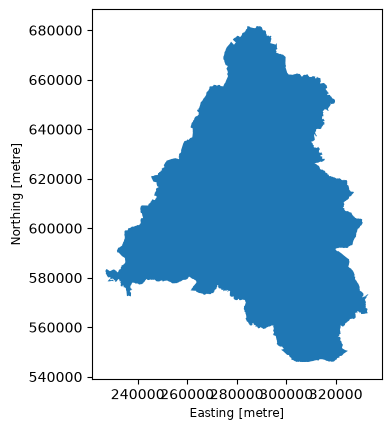

In [17]:
bihor = judete_gdf.loc[judete_gdf["name"] == "Bihor"]
bihor.plot()

In [18]:
path = r"raw_data\Arii_protejate_europa.gpkg"
arii_protejate_europa = gpd.read_file(path)

c:\Users\gblid\.local\share\mamba\envs\solar\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'Arii_protejate_europa.gpkg': 'NaturaSite_polygon' (default), 'BIOREGION', 'DESIGNATIONSTATUS', 'HABITATS', 'HABITATCLASS', 'NATURA2000SITES', 'OTHERSPECIES', 'METADATA', 'IMPACT', 'MANAGEMENT', 'SPECIES'. Specify layer parameter to avoid this warning.
  result = read_func(


In [19]:
arii_protejate_europa.head()

,SITECODE,SITENAME,MS,SITETYPE,INSPIRE_ID,geometry
0,SE0320228,Lunnarna,SE,C,,"POLYGON ((4524927.242 3742218.657, 4525316.92 ..."
1,SE0340103,Kallgatburg,SE,B,,"POLYGON ((4837612.182 3874303.987, 4837684.537..."
2,SE0430147,Jonstorp-Vegeåns mynning,SE,B,,"POLYGON ((4488527.22 3681867.031, 4488538.22 3..."
3,SE0820084,Åträsket,SE,B,,"POLYGON ((4794127.259 4776626.257, 4794127.262..."
4,SE0110366,Ön,SE,B,,"POLYGON ((4801895.819 4110068.269, 4801917.386..."


In [20]:
path = r"raw_data\romania.osm.pbf"
print(pyogrio.list_layers(path))

[['points' 'Point']
 ['lines' 'LineString']
 ['multilinestrings' 'MultiLineString']
 ['multipolygons' 'MultiPolygon']
 ['other_relations' 'GeometryCollection']]


In [21]:
roads = gpd.read_file(path, layer="lines")
roads.head()

,osm_id,name,highway,waterway,aerialway,barrier,man_made,railway,z_order,other_tags,geometry
0,1349,Bulevardul Mircea Eliade,tertiary,NaN,NaN,NaN,NaN,NaN,4,"""is_in:city""=>""București"",""lanes""=>""2"",""maxspe...","LINESTRING (26.09352 44.46932, 26.09355 44.469..."
1,1467,Bulevardul Primăverii,tertiary,NaN,NaN,NaN,NaN,NaN,4,"""is_in:city""=>""București"",""lanes""=>""1"",""maxspe...","LINESTRING (26.09294 44.46977, 26.0928 44.4696..."
2,1759,Strada Răcari,residential,NaN,NaN,NaN,NaN,NaN,3,"""is_in:city""=>""București"",""lanes""=>""2"",""maxspe...","LINESTRING (26.13535 44.41503, 26.13544 44.414..."
3,1760,Calea Dorobanților,primary,NaN,NaN,NaN,NaN,NaN,7,"""cycleway:both""=>""no"",""destination""=>""Urziceni...","LINESTRING (26.08666 44.4658, 26.0868 44.46573..."
4,1915,Bulevardul Camil Ressu,primary,NaN,NaN,NaN,NaN,NaN,7,"""foot""=>""no"",""int_ref""=>""E 81"",""lanes""=>""3"",""l...","LINESTRING (26.14636 44.41759, 26.14648 44.417..."


In [22]:
roads.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [23]:
path = "bihor_roads.osm.pbf"
bihor_gdf = gpd.read_file(path)


DataSourceError: bihor_roads.osm.pbf: No such file or directory

In [ ]:
gpd.list_layers(path)

,name,geometry_type
0,points,Point
1,lines,LineString
2,multilinestrings,MultiLineString
3,multipolygons,MultiPolygon
4,other_relations,GeometryCollection


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

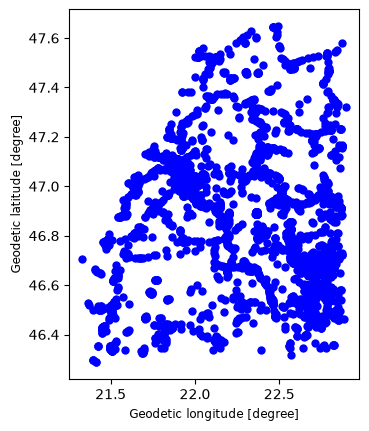

In [ ]:
bihor_gdf.plot(linewidth=0.0002, color="blue")


In [ ]:
bihor_gdf = gpd.read_file(r"data\bihor.gpkg")

In [ ]:
bihor_gdf.crs

<Projected CRS: EPSG:3844>
Name: Pulkovo 1942(58) / Stereo70
Axis Info [cartesian]:
- X[north]: Northing (metre)
- Y[east]: Easting (metre)
Area of Use:
- name: Romania - onshore and offshore.
- bounds: (20.26, 43.44, 31.41, 48.27)
Coordinate Operation:
- name: Stereo 70
- method: Oblique Stereographic
Datum: Pulkovo 1942(58)
- Ellipsoid: Krassowsky 1940
- Prime Meridian: Greenwich

C:\Users\gblid\AppData\Local\Temp\ipykernel_13828\536119719.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  slope = src.read(1)


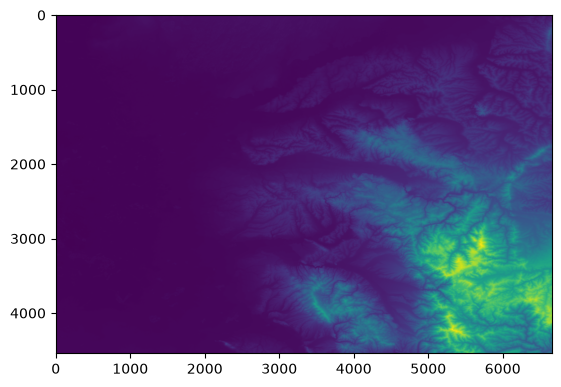

In [ ]:
with rasterio.open(r"raw_data\dem.tif") as src:
    slope = src.read(1)

plt.imshow(slope)
plt.show()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

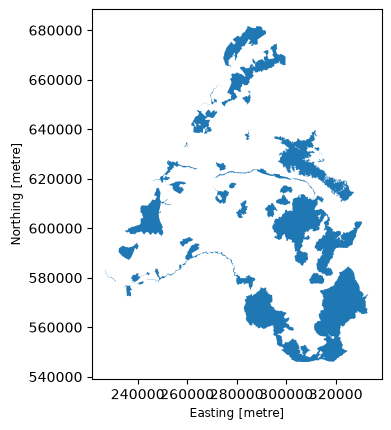

In [ ]:
path = r"data\arii_protejate_bihor.gpkg"
arii_bihor = gpd.read_file(path)
arii_bihor.plot()

In [ ]:
import xarray as xr
import rioxarray

In [ ]:
path = r"raw_data\dem.tif"

data = xr.open_dataset(path, engine="rasterio", masked=True)

In [ ]:
data

<xarray.Dataset> Size: 121MB
Dimensions:      (band: 1, x: 6658, y: 4542)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 53kB 21.21 21.21 21.21 21.21 ... 23.06 23.06 23.06
  * y            (y) float64 36kB 47.61 47.61 47.61 47.61 ... 46.35 46.35 46.35
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) float32 121MB ...

In [ ]:
data = data.rename({"band_data": "elevation"})

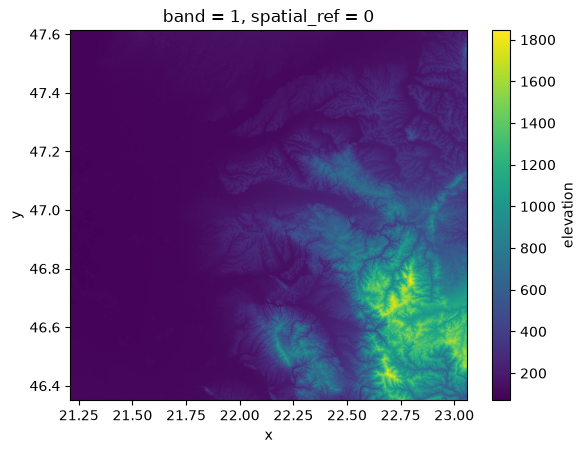

In [ ]:
data["elevation"].plot()

In [ ]:
dim_2d = data["elevation"].squeeze("band",drop=True)

In [ ]:
dim_2d

<xarray.DataArray 'elevation' (y: 4542, x: 6658)> Size: 121MB
[30240636 values with dtype=float32]
Coordinates:
  * y            (y) float64 36kB 47.61 47.61 47.61 47.61 ... 46.35 46.35 46.35
  * x            (x) float64 53kB 21.21 21.21 21.21 21.21 ... 23.06 23.06 23.06
    spatial_ref  int64 8B ...
Attributes:
    AREA_OR_POINT:  Point

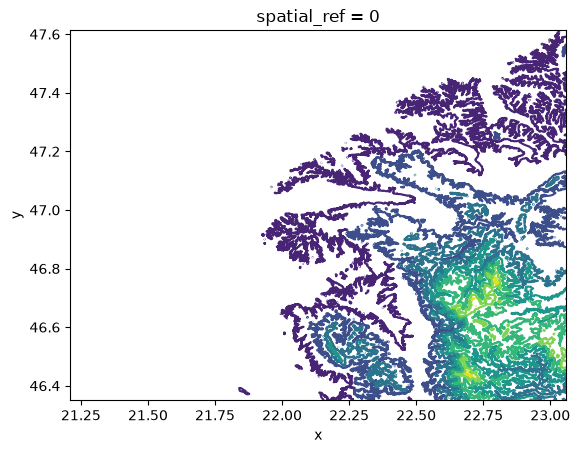

In [ ]:
dim_2d.plot.contour()

Text(0.5, 0.92, '3D surface of the DEM')

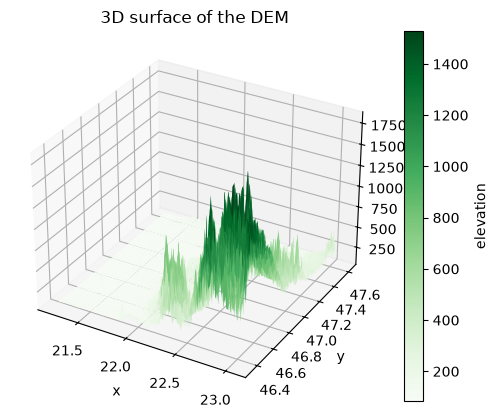

In [ ]:
dim_2d.plot.surface(cmap="Greens")
plt.title("3D surface of the DEM")

In [ ]:
dim_2d.rio.resolution() 

(0.0002777777777777778, -0.0002777777777777778)

In [ ]:
data['elevation'].rio.encoded_nodata

In [ ]:
data['elevation'].nbytes/(1000*1000)

120.962544

In [ ]:
min_elevation = data["elevation"].min().item()
min_elevation

71.37100219726562

In [ ]:
data['elevation'].head()

<xarray.DataArray 'elevation' (band: 1, y: 5, x: 5)> Size: 100B
array([[[87.51614 , 87.41933 , 87.68673 , 87.701195, 87.46144 ],
        [87.66434 , 87.80375 , 87.38088 , 87.461075, 87.46    ],
        [87.431015, 87.66341 , 87.69319 , 87.5874  , 87.749855],
        [87.38517 , 87.74288 , 87.69188 , 87.480865, 87.75845 ],
        [87.58837 , 87.43757 , 87.34433 , 87.50174 , 87.38951 ]]],
      dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 40B 47.61 47.61 47.61 47.61 47.61
  * x            (x) float64 40B 21.21 21.21 21.21 21.21 21.21
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point

In [ ]:
data["relative_height"] = data['elevation'] - min_elevation
data["relative_height"].head()

<xarray.DataArray 'relative_height' (band: 1, y: 5, x: 5)> Size: 100B
array([[[16.145142, 16.048325, 16.315727, 16.330193, 16.090439],
        [16.293335, 16.432747, 16.00988 , 16.090073, 16.088997],
        [16.060013, 16.292404, 16.32219 , 16.2164  , 16.378853],
        [16.014168, 16.37188 , 16.320877, 16.109863, 16.387451],
        [16.21737 , 16.066566, 15.973328, 16.130737, 16.018509]]],
      dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 40B 47.61 47.61 47.61 47.61 47.61
  * x            (x) float64 40B 21.21 21.21 21.21 21.21 21.21
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point

In [ ]:
h= gpd.read_file(r"data\bihor_power.osm.pbf")

c:\Users\gblid\.local\share\mamba\envs\solar\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'bihor_power.osm.pbf': 'points' (default), 'lines', 'multilinestrings', 'multipolygons', 'other_relations'. Specify layer parameter to avoid this warning.
  result = read_func(


In [ ]:
h.explore().save("harta.html")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

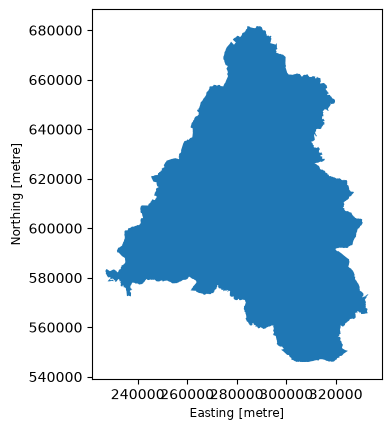

In [1]:
import geopandas as gpd
bihor_gdf = gpd.read_file(r"data\bihor.gpkg")
bihor_gdf.plot()

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

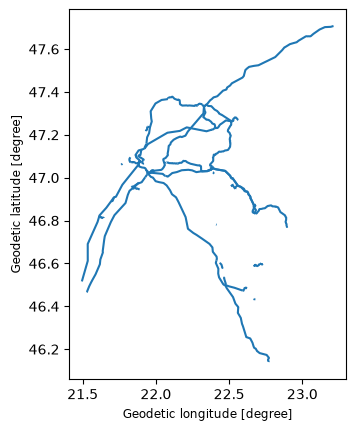

In [6]:
gpd.read_file(r"data\lines.gpkg").plot()

In [9]:
import geopandas as gpd
gpd.read_file("data/substations.gpkg").explore().save("harta.html")

In [10]:
roads = gpd.read_file("data/roads.gpkg")
roads.crs

<Projected CRS: EPSG:3844>
Name: Pulkovo 1942(58) / Stereo70
Axis Info [cartesian]:
- X[north]: Northing (metre)
- Y[east]: Easting (metre)
Area of Use:
- name: Romania - onshore and offshore.
- bounds: (20.26, 43.44, 31.41, 48.27)
Coordinate Operation:
- name: Stereo 70
- method: Oblique Stereographic
Datum: Pulkovo 1942(58)
- Ellipsoid: Krassowsky 1940
- Prime Meridian: Greenwich

In [9]:
import xarray as xr
import rasterio

In [6]:
dem_file = rasterio.open("raw_data/dem.tif")

In [ ]:
dem_file

{'driver': 'GTiff',
 'dtype': 'float32',
 'nodata': None,
 'width': 6658,
 'height': 4542,
 'count': 1,
 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'),
 'transform': Affine(0.0002777777777777778, 0.0, 21.209861100000012,
        0.0, -0.0002777777777777778, 47.61319445555555)}

In [13]:
dem_file = xr.open_dataset("data/PVOUT_bihor.tif", engine="rasterio")

In [28]:
dem_file.rio.resolution()

(30.0, -30.0)

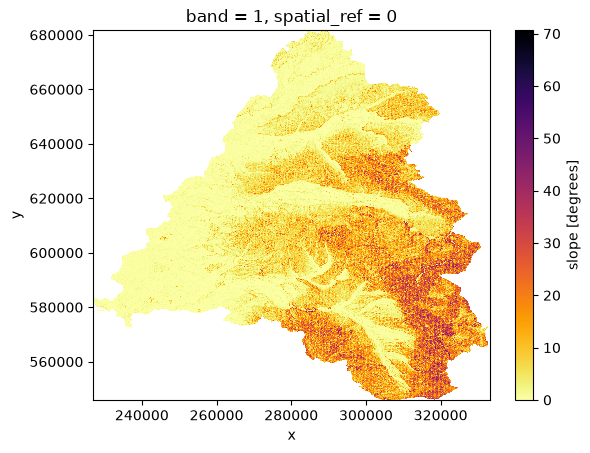

In [7]:
import matplotlib.pyplot as plt
slope_file = xr.open_dataset("data/slope.tif", engine="rasterio") 
slope_file["band_data"].plot(cmap="inferno_r")